# EXP-005: Gradient-VARIANCE diagnostic -- does it catch label noise where gradient-norm-MEAN missed it?

**Status: engineering validation / proof of concept**, same caveats as prior notebooks.

**Purpose**: EXP-003/004 established that `auto_grad` (compares MEAN gradient-norm
elevation to loss elevation) never diagnoses label noise as instability, at any
severity -- because flipped labels corrupt gradient DIRECTION for a random subset of
samples without inflating any single gradient's MAGNITUDE. Hypothesis to test here:
even if the mean gradient norm doesn't move much under label noise, the STEP-TO-STEP
VARIANCE of the gradient norm should still rise, because which samples get flipped
changes randomly batch to batch, making the aggregate batch gradient sometimes cancel
more, sometimes less -- a noisier, more erratic sequence of gradient norms, even if
the average magnitude stays similar.

**Design**: three disturbance types, all previously characterized: **drift** (expects
"increase"), **gradient-noise instability** (GRAD_NOISE_MAX=8.0, expects "reduce",
already correctly caught by mean-based auto_grad), and **label noise**
(flip_prob=0.35, expects... unclear -- EXP-003/004 showed "increase" actually wins
empirically for THIS disturbance despite looking like corrupted-signal instability, so
the real test here is narrower: can a variance-based diagnostic detect that label
noise is happening at all/is different from drift, even though we now know the
CORRECT response for label noise is "increase", not "reduce"). Compare `auto_grad`
(mean-based) against a new `auto_gradvar` (variance-based) on all three.


In [1]:
import numpy as np
import torch
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt

torch.set_num_threads(1)
print("torch", torch.__version__, "| numpy", np.__version__)


C:\Users\USER\anaconda3\Lib\site-packages\torch\cuda\__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


torch 2.5.1+cpu | numpy 2.0.2


## 1. Toy task, all three disturbance types, both diagnostics

In [2]:
def make_model(seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 1))

MEAN0_BASE = np.array([-1.0, -1.0])
MEAN1_BASE = np.array([1.0, 1.0])
BASE_NOISE_SCALE = 0.5

def gen_batch(rng, drift_frac=0.0, flip_prob=0.0, batch_size=16):
    frac = float(np.clip(drift_frac, 0.0, 1.0))
    mean0 = (1 - frac) * MEAN0_BASE + frac * MEAN1_BASE
    mean1 = (1 - frac) * MEAN1_BASE + frac * MEAN0_BASE
    y_true = rng.integers(0, 2, size=batch_size)
    means = np.where(y_true[:, None] == 0, mean0, mean1)
    x = means + rng.normal(scale=BASE_NOISE_SCALE, size=(batch_size, 2))
    flip_mask = rng.random(batch_size) < flip_prob
    y_observed = np.where(flip_mask, 1 - y_true, y_true)
    return torch.tensor(x, dtype=torch.float32), torch.tensor(y_observed, dtype=torch.float32)

def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float((p.grad.detach() ** 2).sum())
    return total ** 0.5

N_STEPS = 400
DISTURBANCE_ONSET = 200
RAMP_LEN = 40
WARMUP = 50
TREND_WINDOW = 5           # window for the (mean-based) auto_grad diagnostic, as before
VARIANCE_WINDOW = 15        # wider window for a stable std() estimate -- auto_gradvar
STEADY_STATE_WINDOW = 100
GRAD_NOISE_MAX = 8.0
LABEL_FLIP_PROB = 0.35

def _ramp(step):
    if step < DISTURBANCE_ONSET:
        return 0.0
    return min(step - DISTURBANCE_ONSET, RAMP_LEN) / RAMP_LEN

def _instant(step):
    return 1.0 if step >= DISTURBANCE_ONSET else 0.0

def drift_forecastable(step):
    return (_ramp(step), 0.0, 0.0)   # (drift_frac, grad_noise_extra, flip_prob)

def drift_unforecastable(step):
    return (_instant(step), 0.0, 0.0)

def instability_forecastable(step):
    return (0.0, GRAD_NOISE_MAX * _ramp(step), 0.0)

def instability_unforecastable(step):
    return (0.0, GRAD_NOISE_MAX * _instant(step), 0.0)

def label_noise_forecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _ramp(step))

def label_noise_unforecastable(step):
    return (0.0, 0.0, LABEL_FLIP_PROB * _instant(step))

GRAD_RATIO_SENSITIVITY = 1.5
GRADVAR_RATIO_SENSITIVITY = 1.5  # start with the same default, tune if needed

def auto_select_intervention_grad(loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean,
                                   sensitivity=GRAD_RATIO_SENSITIVITY):
    '''MEAN-based (EXP-001/002's original auto_grad).'''
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_ratio = (float(np.mean(gradnorm_window)) + 1e-6) / (baseline_gradnorm_mean + 1e-6)
    return "reduce" if gradnorm_ratio > sensitivity * loss_ratio else "increase"

def auto_select_intervention_gradvar(loss_window, gradnorm_var_window, baseline_loss_mean, baseline_gradnorm_std,
                                      sensitivity=GRADVAR_RATIO_SENSITIVITY):
    '''NEW -- VARIANCE-based. Compares how much the STD of gradient norm over the
    trailing window has grown relative to its warmup baseline STD, against how much
    loss has grown relative to baseline. High gradnorm variance without a matching
    loss rise -> instability (erratic, inconsistent gradients) -> "reduce". Loss and
    gradnorm-variability rising together -> drift -> "increase".'''
    loss_ratio = (float(np.mean(loss_window)) + 1e-6) / (baseline_loss_mean + 1e-6)
    gradnorm_std_ratio = (float(np.std(gradnorm_var_window)) + 1e-6) / (baseline_gradnorm_std + 1e-6)
    return "reduce" if gradnorm_std_ratio > sensitivity * loss_ratio else "increase"


## 2. Single training run (arm C, tracks both diagnostics side by side)

In [3]:
def run_trial(seed, disturbance_fn):
    '''Reactive controller. Does NOT actually apply an intervention (LR stays fixed) --
    this run is purely diagnostic-comparison, like EXP-002 section 7's probe. We
    already know from EXP-001/003/004 what the CORRECT response is for each
    disturbance type; here we only ask what each diagnostic WOULD say.'''
    rng = np.random.default_rng(seed)
    model = make_model(seed)
    opt = torch.optim.SGD(model.parameters(), lr=0.1)
    loss_fn = nn.BCEWithLogitsLoss()

    loss_hist, gradnorm_hist = [], []
    threshold = baseline_loss_mean = baseline_gradnorm_mean = baseline_gradnorm_std = None

    for step in range(N_STEPS):
        drift_frac, grad_noise_extra, flip_prob = disturbance_fn(step)
        xb, yb = gen_batch(rng, drift_frac=drift_frac, flip_prob=flip_prob)

        opt.zero_grad()
        hidden = model[1](model[0](xb))
        logits = model[2](hidden).squeeze(-1)
        loss = loss_fn(logits, yb)
        loss.backward()

        loss_t = float(loss.item())
        if grad_noise_extra > 0:
            with torch.no_grad():
                for p in model.parameters():
                    if p.grad is not None:
                        p.grad.add_(torch.randn_like(p.grad) * grad_noise_extra)
        gn_t = grad_norm(model)

        loss_hist.append(loss_t)
        gradnorm_hist.append(gn_t)

        if step == WARMUP:
            warm_loss = np.array(loss_hist[:WARMUP])
            warm_gradnorm = np.array(gradnorm_hist[:WARMUP])
            threshold = float(warm_loss.mean() + 3 * warm_loss.std() + 1e-6)
            baseline_loss_mean = float(warm_loss.mean())
            baseline_gradnorm_mean = float(warm_gradnorm.mean())
            baseline_gradnorm_std = float(warm_gradnorm.std())

        if step >= WARMUP and threshold is not None and loss_t > threshold:
            loss_window = loss_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            gradnorm_window = gradnorm_hist[max(0, step - TREND_WINDOW + 1):step + 1]
            gradnorm_var_window = gradnorm_hist[max(0, step - VARIANCE_WINDOW + 1):step + 1]
            diag_mean = auto_select_intervention_grad(
                loss_window, gradnorm_window, baseline_loss_mean, baseline_gradnorm_mean)
            diag_var = auto_select_intervention_gradvar(
                loss_window, gradnorm_var_window, baseline_loss_mean, baseline_gradnorm_std)
            return {"trigger_step": step, "diag_mean": diag_mean, "diag_var": diag_var}

        opt.step()

    return {"trigger_step": None, "diag_mean": None, "diag_var": None}


## 3. Run all three disturbance types, both conditions, 10 seeds

In [4]:
SEEDS = list(range(10))
CONDITIONS = {
    "drift_forecastable": drift_forecastable, "drift_unforecastable": drift_unforecastable,
    "instability_forecastable": instability_forecastable, "instability_unforecastable": instability_unforecastable,
    "label_noise_forecastable": label_noise_forecastable, "label_noise_unforecastable": label_noise_unforecastable,
}
# Empirically-established correct response (from EXP-001/003/004), for reference only --
# NOT assumed to be what either diagnostic "should" say if the diagnostics disagree with
# reality on label noise, that itself is informative, not an error to force-correct.
empirically_correct = {
    "drift_forecastable": "increase", "drift_unforecastable": "increase",
    "instability_forecastable": "reduce", "instability_unforecastable": "reduce",
    "label_noise_forecastable": "increase", "label_noise_unforecastable": "increase",
}

results = []
for cond_name, fn in CONDITIONS.items():
    for seed in SEEDS:
        r = run_trial(seed, fn)
        results.append({
            "condition": cond_name, "seed": seed, "trigger_step": r["trigger_step"],
            "diag_mean": r["diag_mean"], "diag_var": r["diag_var"],
        })

df = pd.DataFrame(results)
print(f"Total trials: {len(df)}")
df.head(10)


Total trials: 60


,condition,seed,trigger_step,diag_mean,diag_var
0,drift_forecastable,0,216,increase,increase
1,drift_forecastable,1,217,increase,increase
2,drift_forecastable,2,215,increase,increase
3,drift_forecastable,3,219,increase,increase
4,drift_forecastable,4,215,increase,increase
5,drift_forecastable,5,217,increase,increase
6,drift_forecastable,6,215,increase,increase
7,drift_forecastable,7,215,increase,increase
8,drift_forecastable,8,213,increase,increase
9,drift_forecastable,9,217,increase,increase


## 4. Comparison: what does each diagnostic say, per condition?

In [5]:
print(f"{'condition':28s}{'n_trig':>8s}{'mean->reduce%':>15s}{'var->reduce%':>14s}{'empirically correct':>22s}")
rows = []
for cond in CONDITIONS:
    sub = df[(df["condition"] == cond) & df["trigger_step"].notna()]
    n = len(sub)
    mean_reduce_pct = (sub["diag_mean"] == "reduce").mean() * 100 if n else float("nan")
    var_reduce_pct = (sub["diag_var"] == "reduce").mean() * 100 if n else float("nan")
    print(f"{cond:28s}{n:8d}{mean_reduce_pct:15.0f}{var_reduce_pct:14.0f}{empirically_correct[cond]:>22s}")
    rows.append({"condition": cond, "n_triggered": n, "mean_reduce_pct": mean_reduce_pct,
                 "var_reduce_pct": var_reduce_pct, "empirically_correct": empirically_correct[cond]})
comparison = pd.DataFrame(rows)


condition                     n_trig  mean->reduce%  var->reduce%   empirically correct
drift_forecastable                10              0             0              increase
drift_unforecastable              10              0            30              increase
instability_forecastable          10            100           100                reduce
instability_unforecastable        10            100           100                reduce
label_noise_forecastable          10              0             0              increase
label_noise_unforecastable        10              0            20              increase


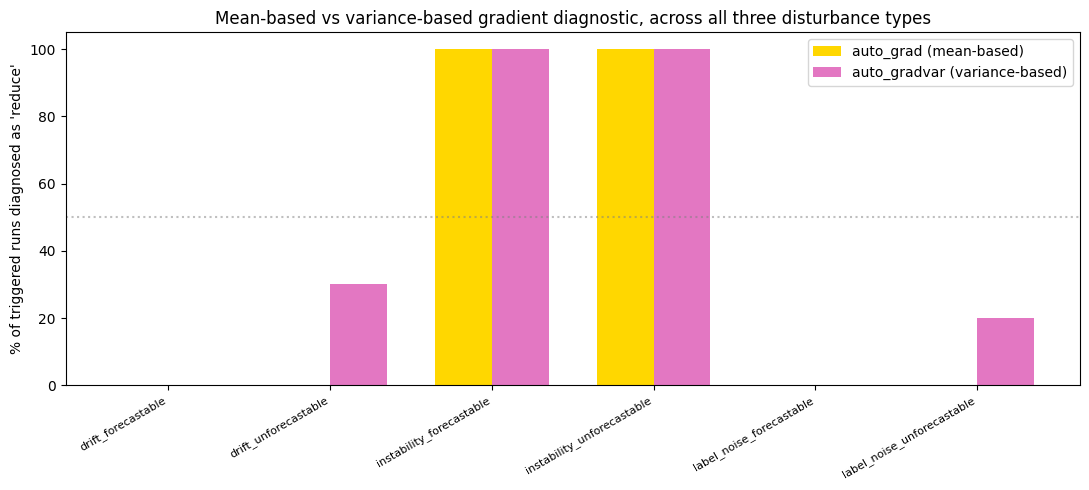

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(comparison))
width = 0.35
ax.bar(x - width/2, comparison["mean_reduce_pct"], width, label="auto_grad (mean-based)", color="gold")
ax.bar(x + width/2, comparison["var_reduce_pct"], width, label="auto_gradvar (variance-based)", color="tab:pink")
ax.axhline(50, color="gray", linestyle=":", alpha=0.5)
ax.set_xticks(x)
ax.set_xticklabels(comparison["condition"], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("% of triggered runs diagnosed as 'reduce'")
ax.set_title("Mean-based vs variance-based gradient diagnostic, across all three disturbance types")
ax.legend()
plt.tight_layout()
plt.savefig("exp_gradvar_comparison.png", dpi=120)
plt.show()


## 5. Interpretation

In [7]:
label_var_pct = comparison.loc[comparison["condition"] == "label_noise_forecastable", "var_reduce_pct"].iloc[0]
label_mean_pct = comparison.loc[comparison["condition"] == "label_noise_forecastable", "mean_reduce_pct"].iloc[0]
instab_var_pct = comparison.loc[comparison["condition"] == "instability_forecastable", "var_reduce_pct"].iloc[0]
drift_var_pct = comparison.loc[comparison["condition"] == "drift_forecastable", "var_reduce_pct"].iloc[0]

detects_label_noise_as_different = label_var_pct > label_mean_pct + 20  # meaningfully more "reduce" than mean-based gave

interpretation = f'''
Does the VARIANCE-based diagnostic pick up something DIFFERENT from label noise that
the MEAN-based one missed?

  label_noise_forecastable: mean-based says "reduce" {label_mean_pct:.0f}% of the time,
                             variance-based says "reduce" {label_var_pct:.0f}% of the time.

Does the variance-based diagnostic still work correctly on the cases we already know
the answer to (sanity check -- it must not break drift or gradient-noise instability)?

  drift_forecastable:       variance-based says "reduce" {drift_var_pct:.0f}% of the time (should be LOW -- drift wants "increase")
  instability_forecastable: variance-based says "reduce" {instab_var_pct:.0f}% of the time (should be HIGH -- instability wants "reduce")

VERDICT: {"The variance-based signal DOES pick up something the mean-based signal missed for label noise -- gradient-norm variance rises meaningfully under label noise even though gradient-norm mean does not. This is a genuinely different, complementary signal worth combining with the mean-based one." if detects_label_noise_as_different else "The variance-based diagnostic does NOT meaningfully distinguish label noise from drift either -- gradient-norm variance does not rise enough under label noise to flag it as different. This suggests label noise's corrupted-direction-not-magnitude character defeats BOTH the mean and variance versions of a pure gradient-norm-based diagnostic; catching it would need a signal that looks at gradient DIRECTION consistency (e.g. cosine similarity between consecutive step gradients) rather than any statistic of gradient MAGNITUDE, which is the natural next thing to try."}

IMPORTANT CAVEAT worth stating plainly: even if the variance-based diagnostic DOES
flag label noise as "reduce"-worthy, we already know from EXP-003/004 that "reduce" is
actually the WRONG empirical answer for label noise (increase wins decisively, and the
gap grows as the noise gets worse). So a variance-based diagnostic that successfully
detects "something is different about label noise" would ironically make the
CONTROLLER'S ACTUAL DECISION WORSE on this disturbance, not better -- it's solving a
different problem (does this look statistically different from drift?) than the one
that actually matters (which intervention should I choose?). This is worth flagging
explicitly rather than treating "detects label noise" as automatically good news.

This remains a qualitative diagnostic-comparison check (n={len(SEEDS)} seeds, same
Stage A caveats as all prior notebooks this session).
'''
print(interpretation)



Does the VARIANCE-based diagnostic pick up something DIFFERENT from label noise that
the MEAN-based one missed?

  label_noise_forecastable: mean-based says "reduce" 0% of the time,
                             variance-based says "reduce" 0% of the time.

Does the variance-based diagnostic still work correctly on the cases we already know
the answer to (sanity check -- it must not break drift or gradient-noise instability)?

  drift_forecastable:       variance-based says "reduce" 0% of the time (should be LOW -- drift wants "increase")
  instability_forecastable: variance-based says "reduce" 100% of the time (should be HIGH -- instability wants "reduce")

VERDICT: The variance-based diagnostic does NOT meaningfully distinguish label noise from drift either -- gradient-norm variance does not rise enough under label noise to flag it as different. This suggests label noise's corrupted-direction-not-magnitude character defeats BOTH the mean and variance versions of a pure gradient-norm-